## this notebook examplifies the spectral filter T5-42

In [15]:
import xarray as xr
import cartopy.crs as ccrs
import numpy as np
from pystormtracker.preprocessing import SHTFilter
import sys
import os
from pathlib import Path

module_dir = (Path.cwd() / ".."/".." / "algorithms"/ "track_style_alg").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *
from plotting import *

In [17]:
SHTFilter?

Init signature:
SHTFilter(
    lmin: 'int',
    lmax: 'int',
    lat_reverse: 'bool' = False,
    taper_val: 'float' = 0.1,
    geometry: "Literal['CC', 'GL', 'DH', 'auto']" = 'auto',
    out_geometry: 'str | None' = None,
    out_ntheta: 'int | None' = None,
    out_nphi: 'int | None' = None,
    sht_threads: 'int | None' = None,
) -> 'None'
Docstring:     
Global spherical-harmonic bandpass filter using ``ducc0``.

The published spherical smoothing lineage is Sardeshmukh and Hoskins
(1984); ``ducc0`` supplies the numerical SHT implementation and PST owns
the filter wrapper and coefficient-mask integration.
Init docstring:
Initialize the filter with wave number bounds.

Args:
    lmin (int): Minimum total wave number to retain.
    lmax (int): Maximum total wave number to retain.
    lat_reverse (bool): If True, assume latitude is North to South (reversed).
    taper_val (float): Value of the taper at lmax.
    geometry (str): Grid geometry ('CC', 'GL', 'DH', or 'auto').
    out_geome

In [18]:
ds = xr.open_dataset('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5_pressure_levels/19981999_DJF_globe.nc')
vo = ds['vo'].sel(pressure_level=850).isel(valid_time = 0)*1e5
ds

<xarray.Dataset> Size: 3GB
Dimensions:         (valid_time: 720, pressure_level: 1, latitude: 721,
                     longitude: 1440)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
    number          int64 8B ...
Data variables:
    vo              (valid_time, pressure_level, latitude, longitude) float32 3GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-16T08:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [19]:
ds_coarse = xr.open_dataset('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5_pressure_levels/19981999_DJF_globe_fejer.nc')
vo_coarse = ds_coarse['vo'].sel(pressure_level=850).isel(valid_time = 0)*1e5
ds_coarse

<xarray.Dataset> Size: 332MB
Dimensions:         (valid_time: 720, pressure_level: 1, lat: 240, lon: 480)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
  * pressure_level  (pressure_level) float64 8B 850.0
  * lat             (lat) float64 2kB -89.62 -88.88 -88.12 ... 88.12 88.88 89.62
  * lon             (lon) float64 4kB 0.0 0.75 1.5 2.25 ... 357.8 358.5 359.2
Data variables:
    vo              (valid_time, pressure_level, lat, lon) float32 332MB ...
Attributes:
    CDI:                     Climate Data Interface version 2.5.0 (https://mp...
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    history:                 Fri Oct 30 16:25:37 2026: cdo remapcon,r480x240 ...
    CDO:                     Climate Data Operators version 2.5.0 (https://mp...

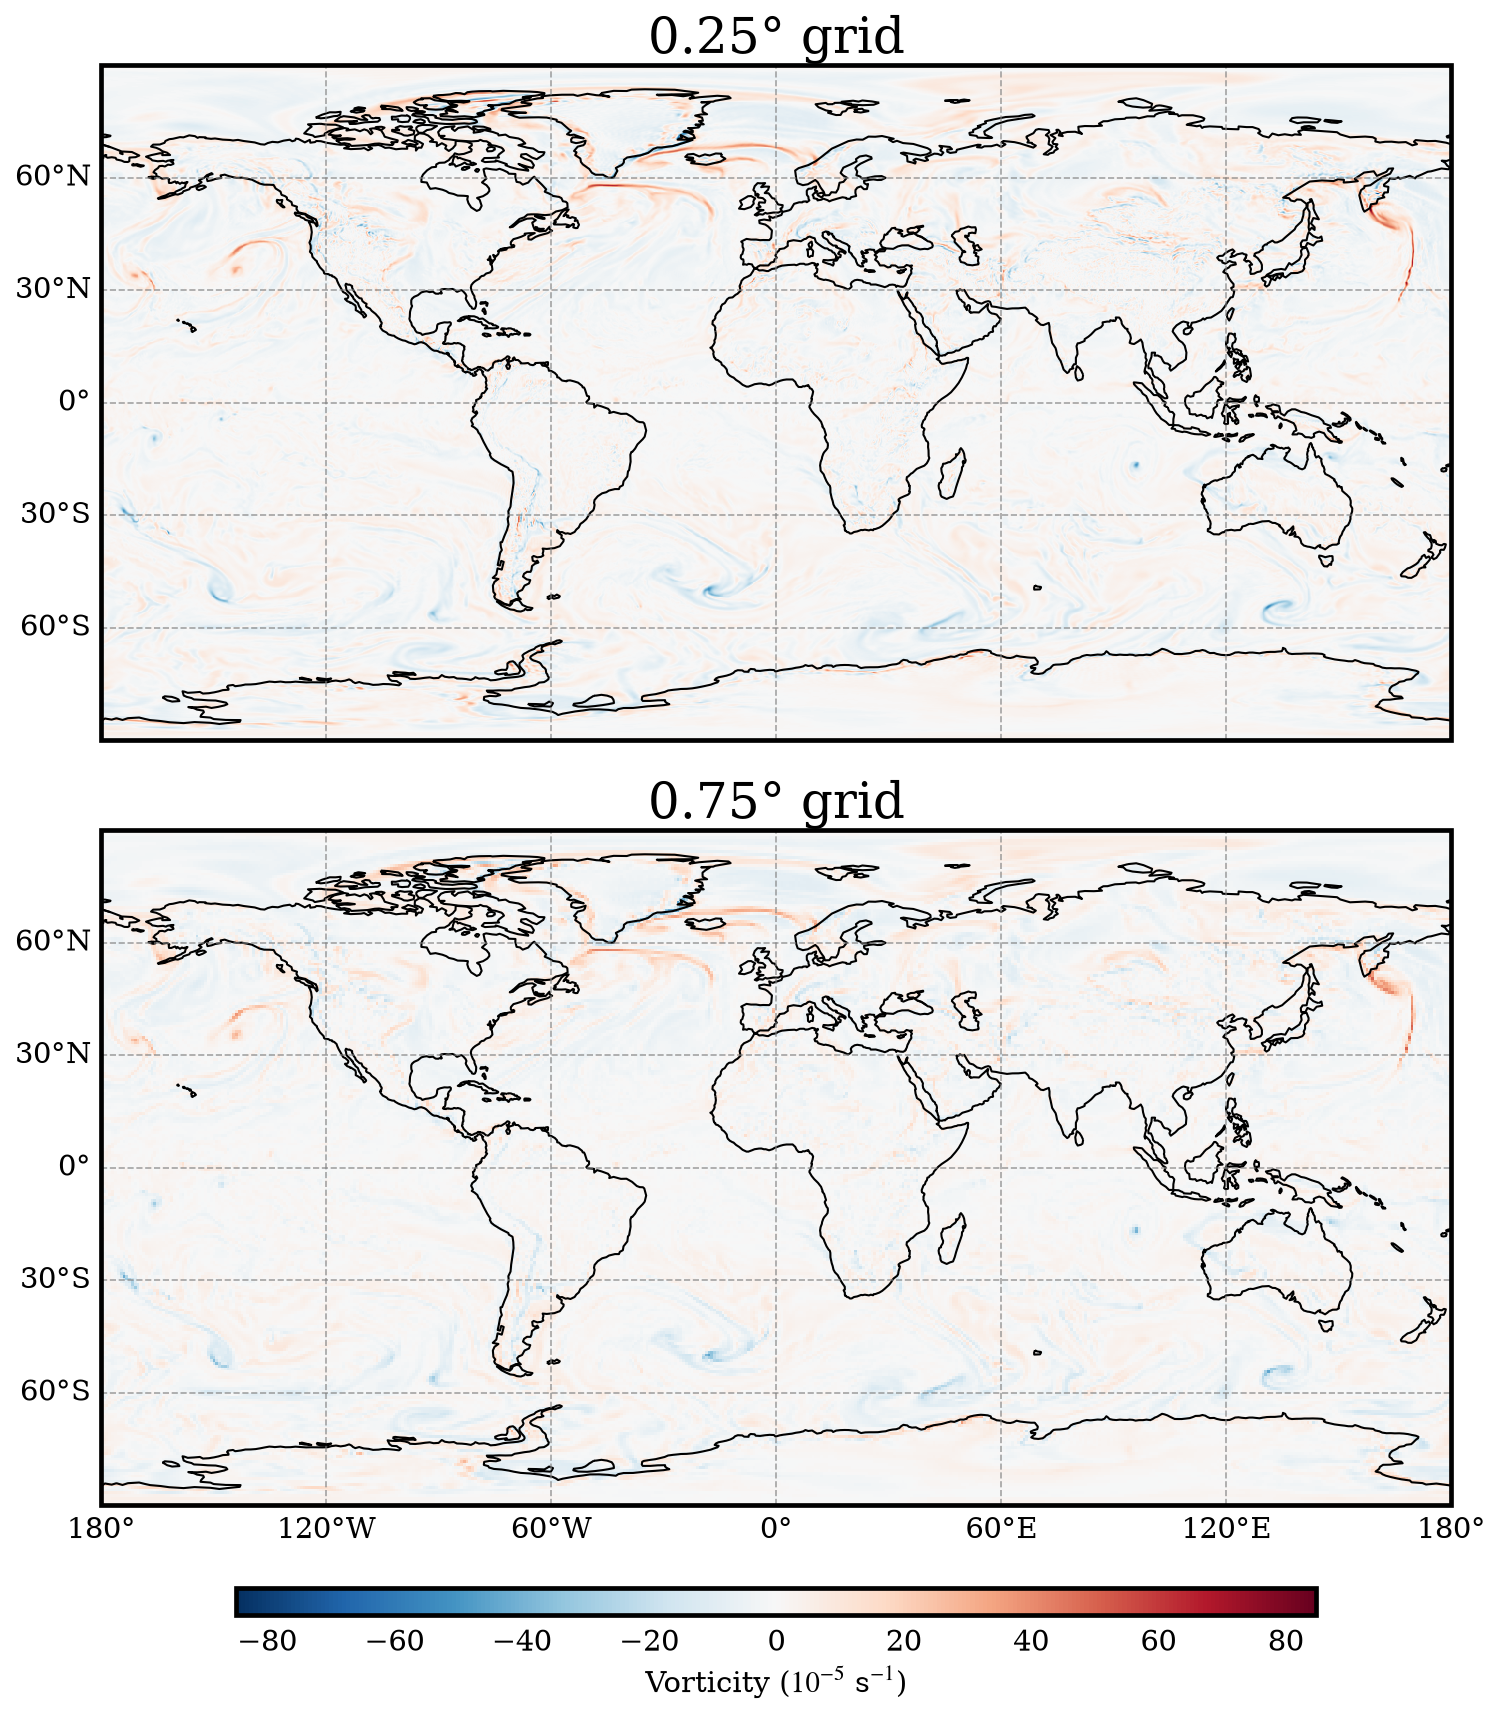

In [20]:
import cartopy.crs as ccrs


setup_plotting()

vmax = float(abs(vo).max())               # symmetric limits so white = 0

fig, ax = geo_map(nrows=2)                # sized to fit, constrained layout
for a, da, title in zip(ax, [vo, vo_coarse], ["0.25° grid", "0.75° grid"]):
    im = da.plot(ax=a, transform=ccrs.PlateCarree(), cmap="RdBu_r",
                 vmin=-vmax, vmax=vmax, add_colorbar=False)
    a.set_title(title)

add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", labelsize=14)





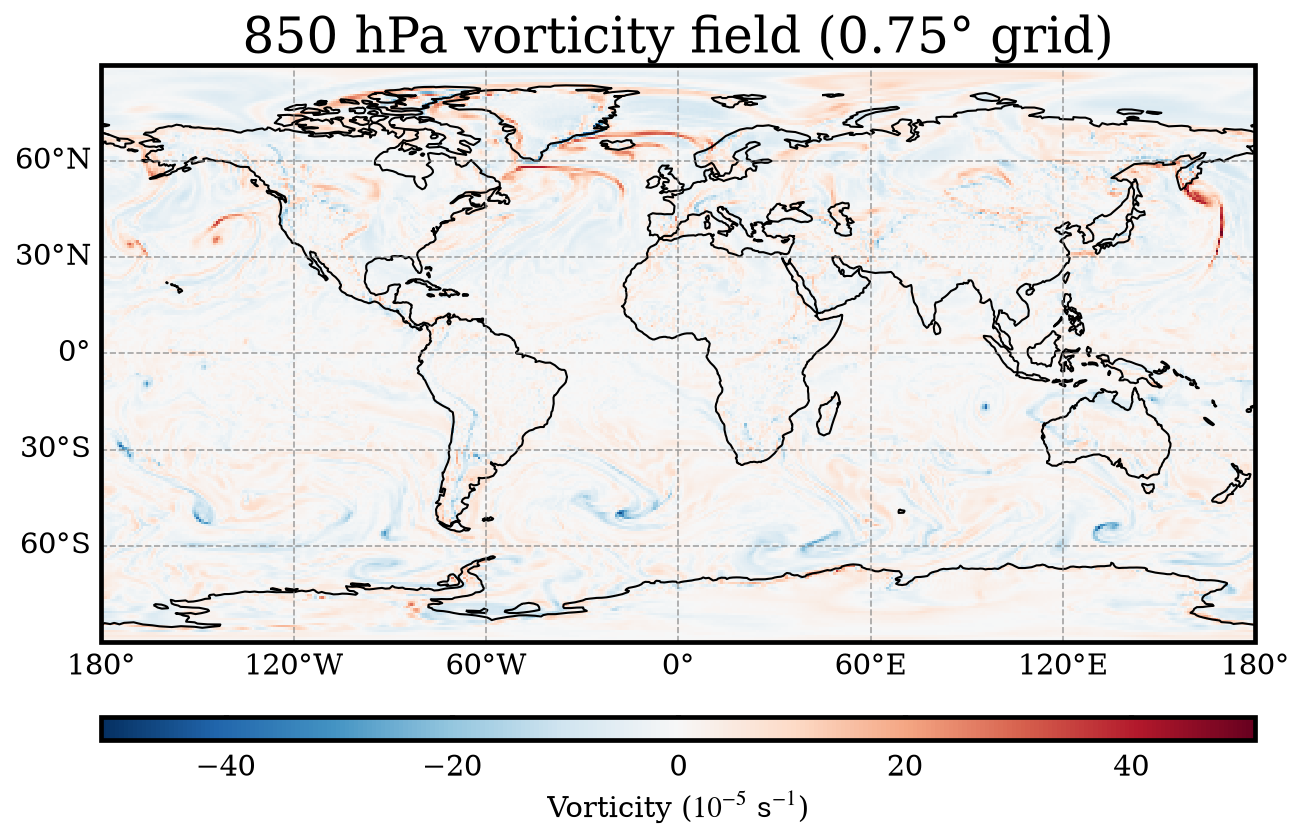

In [21]:
vmax = float(abs(vo_coarse).max())

fig, ax = geo_map()
im = vo_coarse.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
                    vmin=-vmax, vmax=vmax, add_colorbar=False)
ax.set_title("850 hPa vorticity field (0.75° grid)")

add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", pad=0.5, labelsize=14)

In [22]:
lmin = 5
lmax = 42

vo_filtered_5 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo)
vo_coarse_filtered_5 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo_coarse)

In [23]:
lmin=6
lmax=42
vo_filtered_6 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo)
vo_coarse_filtered_6 = SHTFilter(lmin=lmin, lmax=lmax, taper_val=0.1).filter(vo_coarse)

In [24]:
diff_5 = vo - vo_filtered_5
diff_6 = vo - vo_filtered_6
diff_5_6 = vo_filtered_5 - vo_filtered_6

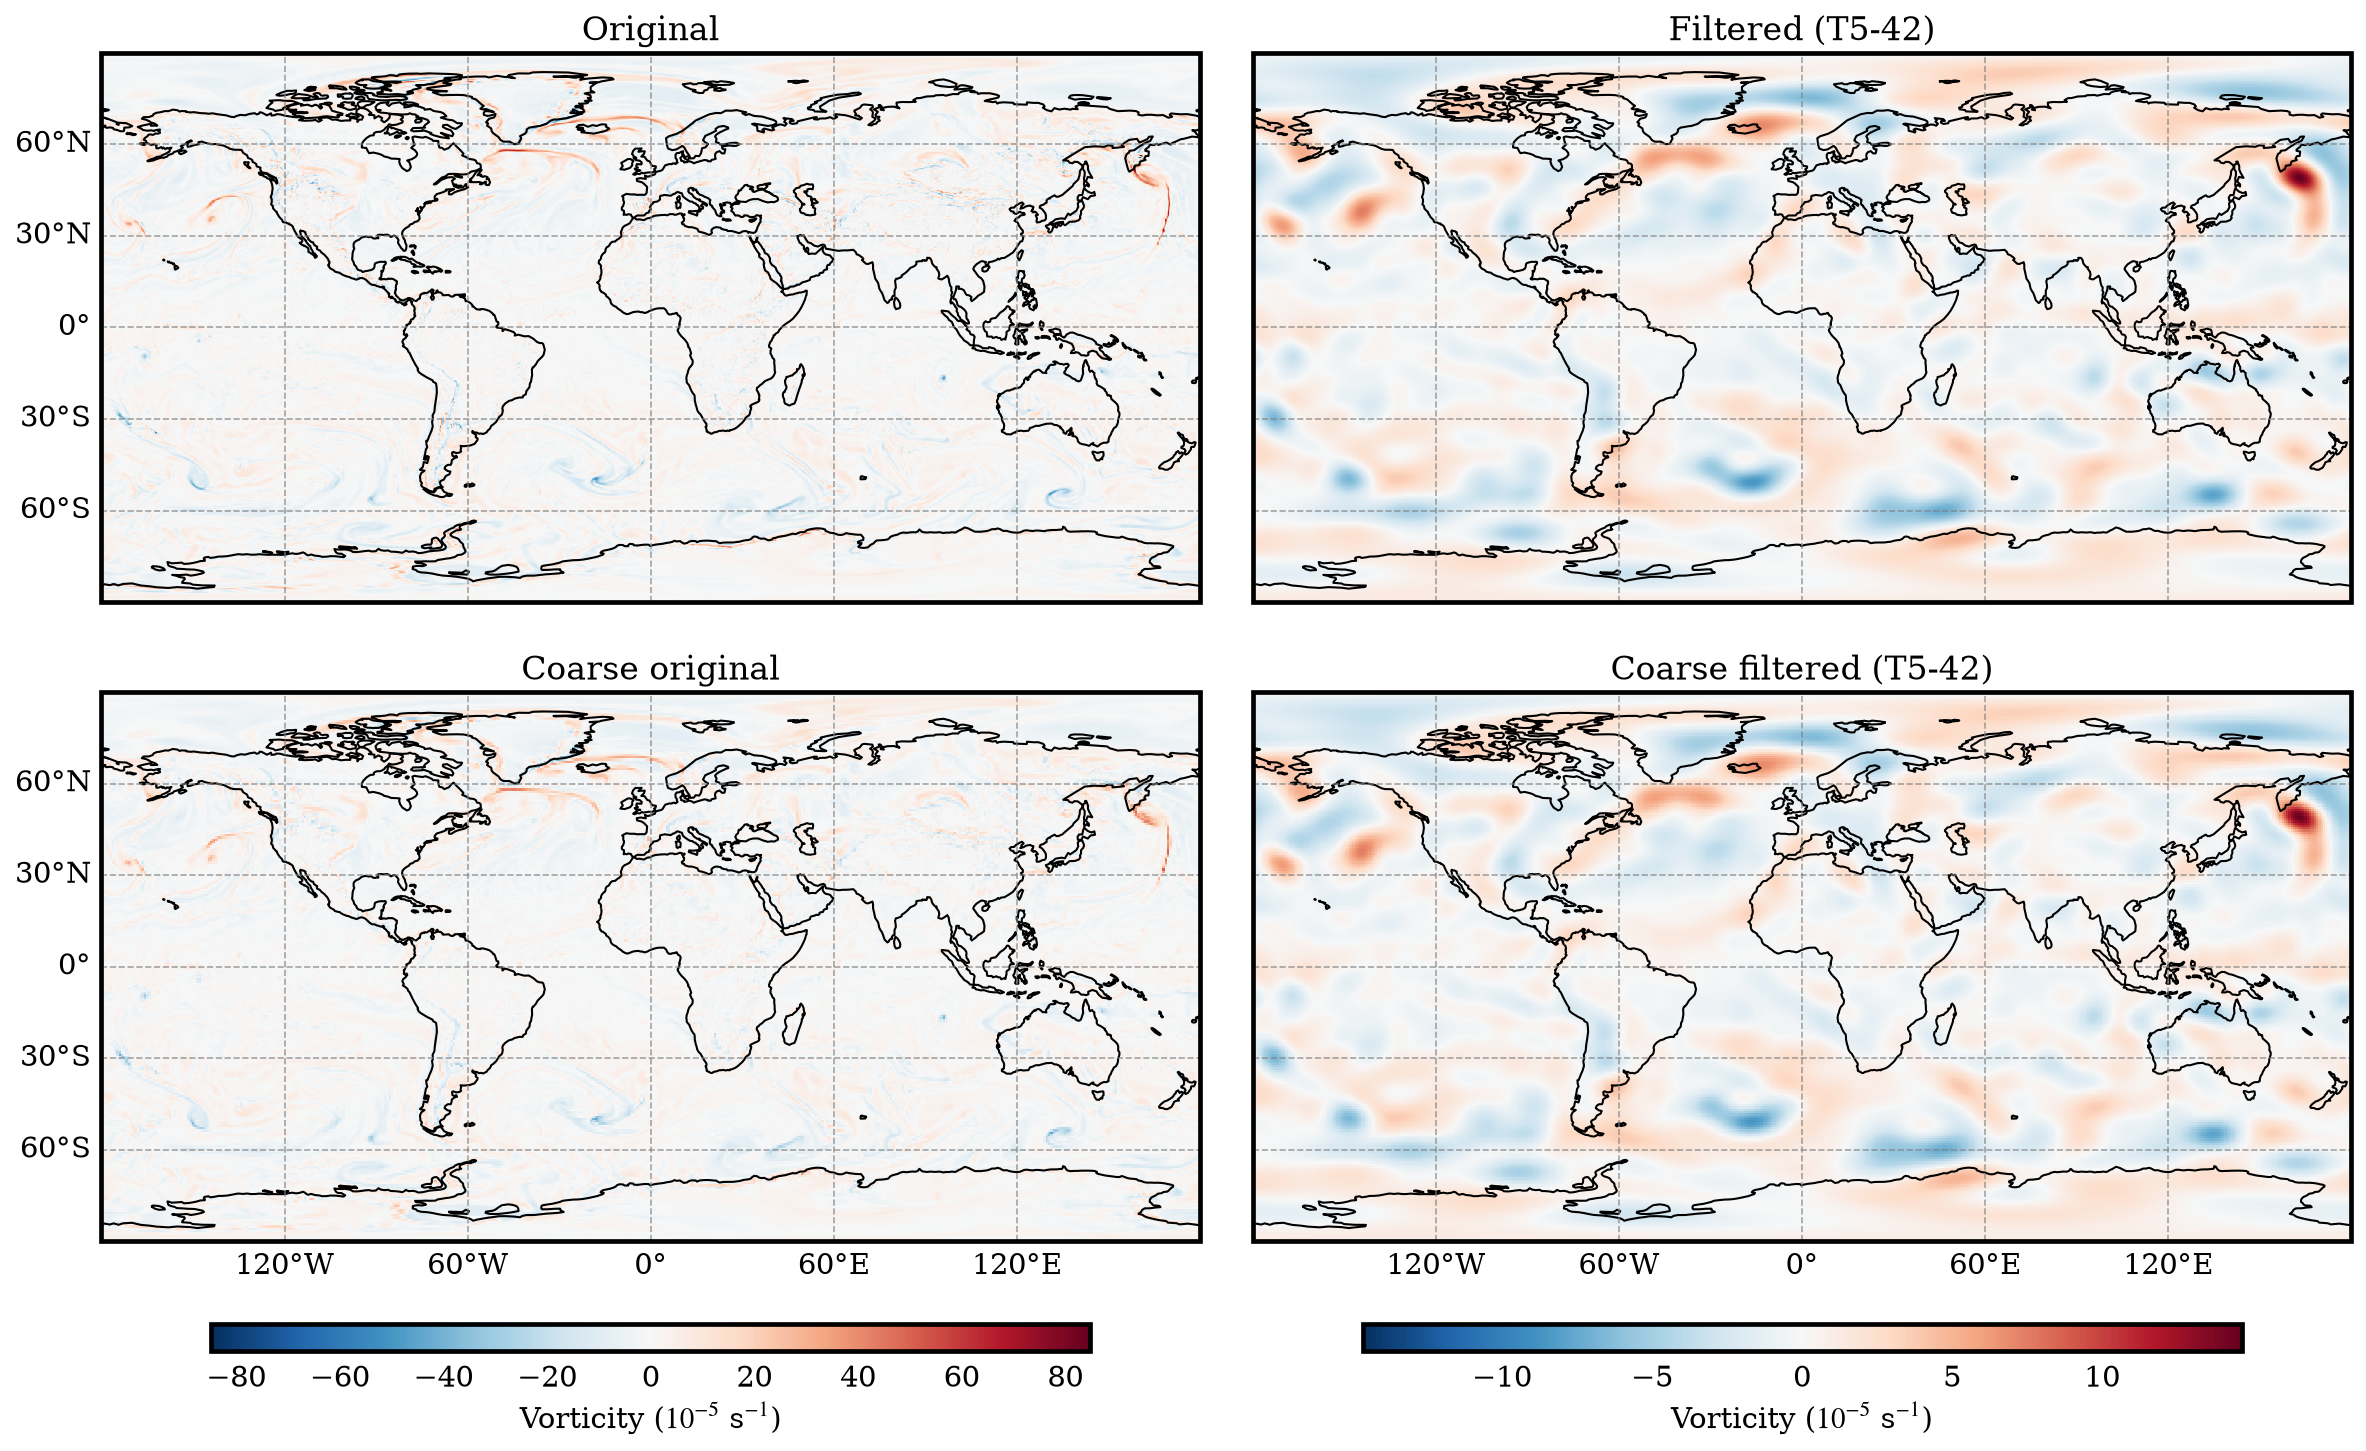

In [29]:
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import Gridliner

label = r"Vorticity ($10^{-5}$ s$^{-1}$)"
fields = [[vo, vo_filtered_6],
          [vo_coarse, vo_coarse_filtered_6]]
titles = [["Original", "Filtered (T5-42)"],
          ["Coarse original", "Coarse filtered (T5-42)"]]

# symmetric limits so white = 0; originals and filtered fields get separate scales
vmax_orig = float(max(abs(fields[0][0]).max(), abs(fields[1][0]).max()))
vmax_filt = float(max(abs(f).max() for row in fields for f in row[1:]))

fig, ax = geo_map(nrows=2, ncols=2, width=16)
for a in ax.flat:  # drop the ±180° labels, which collide between neighbouring maps
    for gl in (art for art in a.artists if isinstance(art, Gridliner)):
        gl.xlocator = mticker.FixedLocator([-120, -60, 0, 60, 120])
for i in range(2):
    for j in range(2):
        vmax = vmax_orig if j == 0 else vmax_filt
        im = fields[i][j].plot(ax=ax[i, j], transform=ccrs.PlateCarree(), cmap="RdBu_r",
                               vmin=-vmax, vmax=vmax, add_colorbar=False)
        ax[i, j].set_title(titles[i][j], fontsize=16)
        if j == 0:
            im_orig = im
        else:
            im_filt = im

add_colorbar(im_orig, ax[:, 0], label=label, location="bottom", labelsize=14)
add_colorbar(im_filt, ax[:, 1:], label=label, location="bottom", labelsize=14)

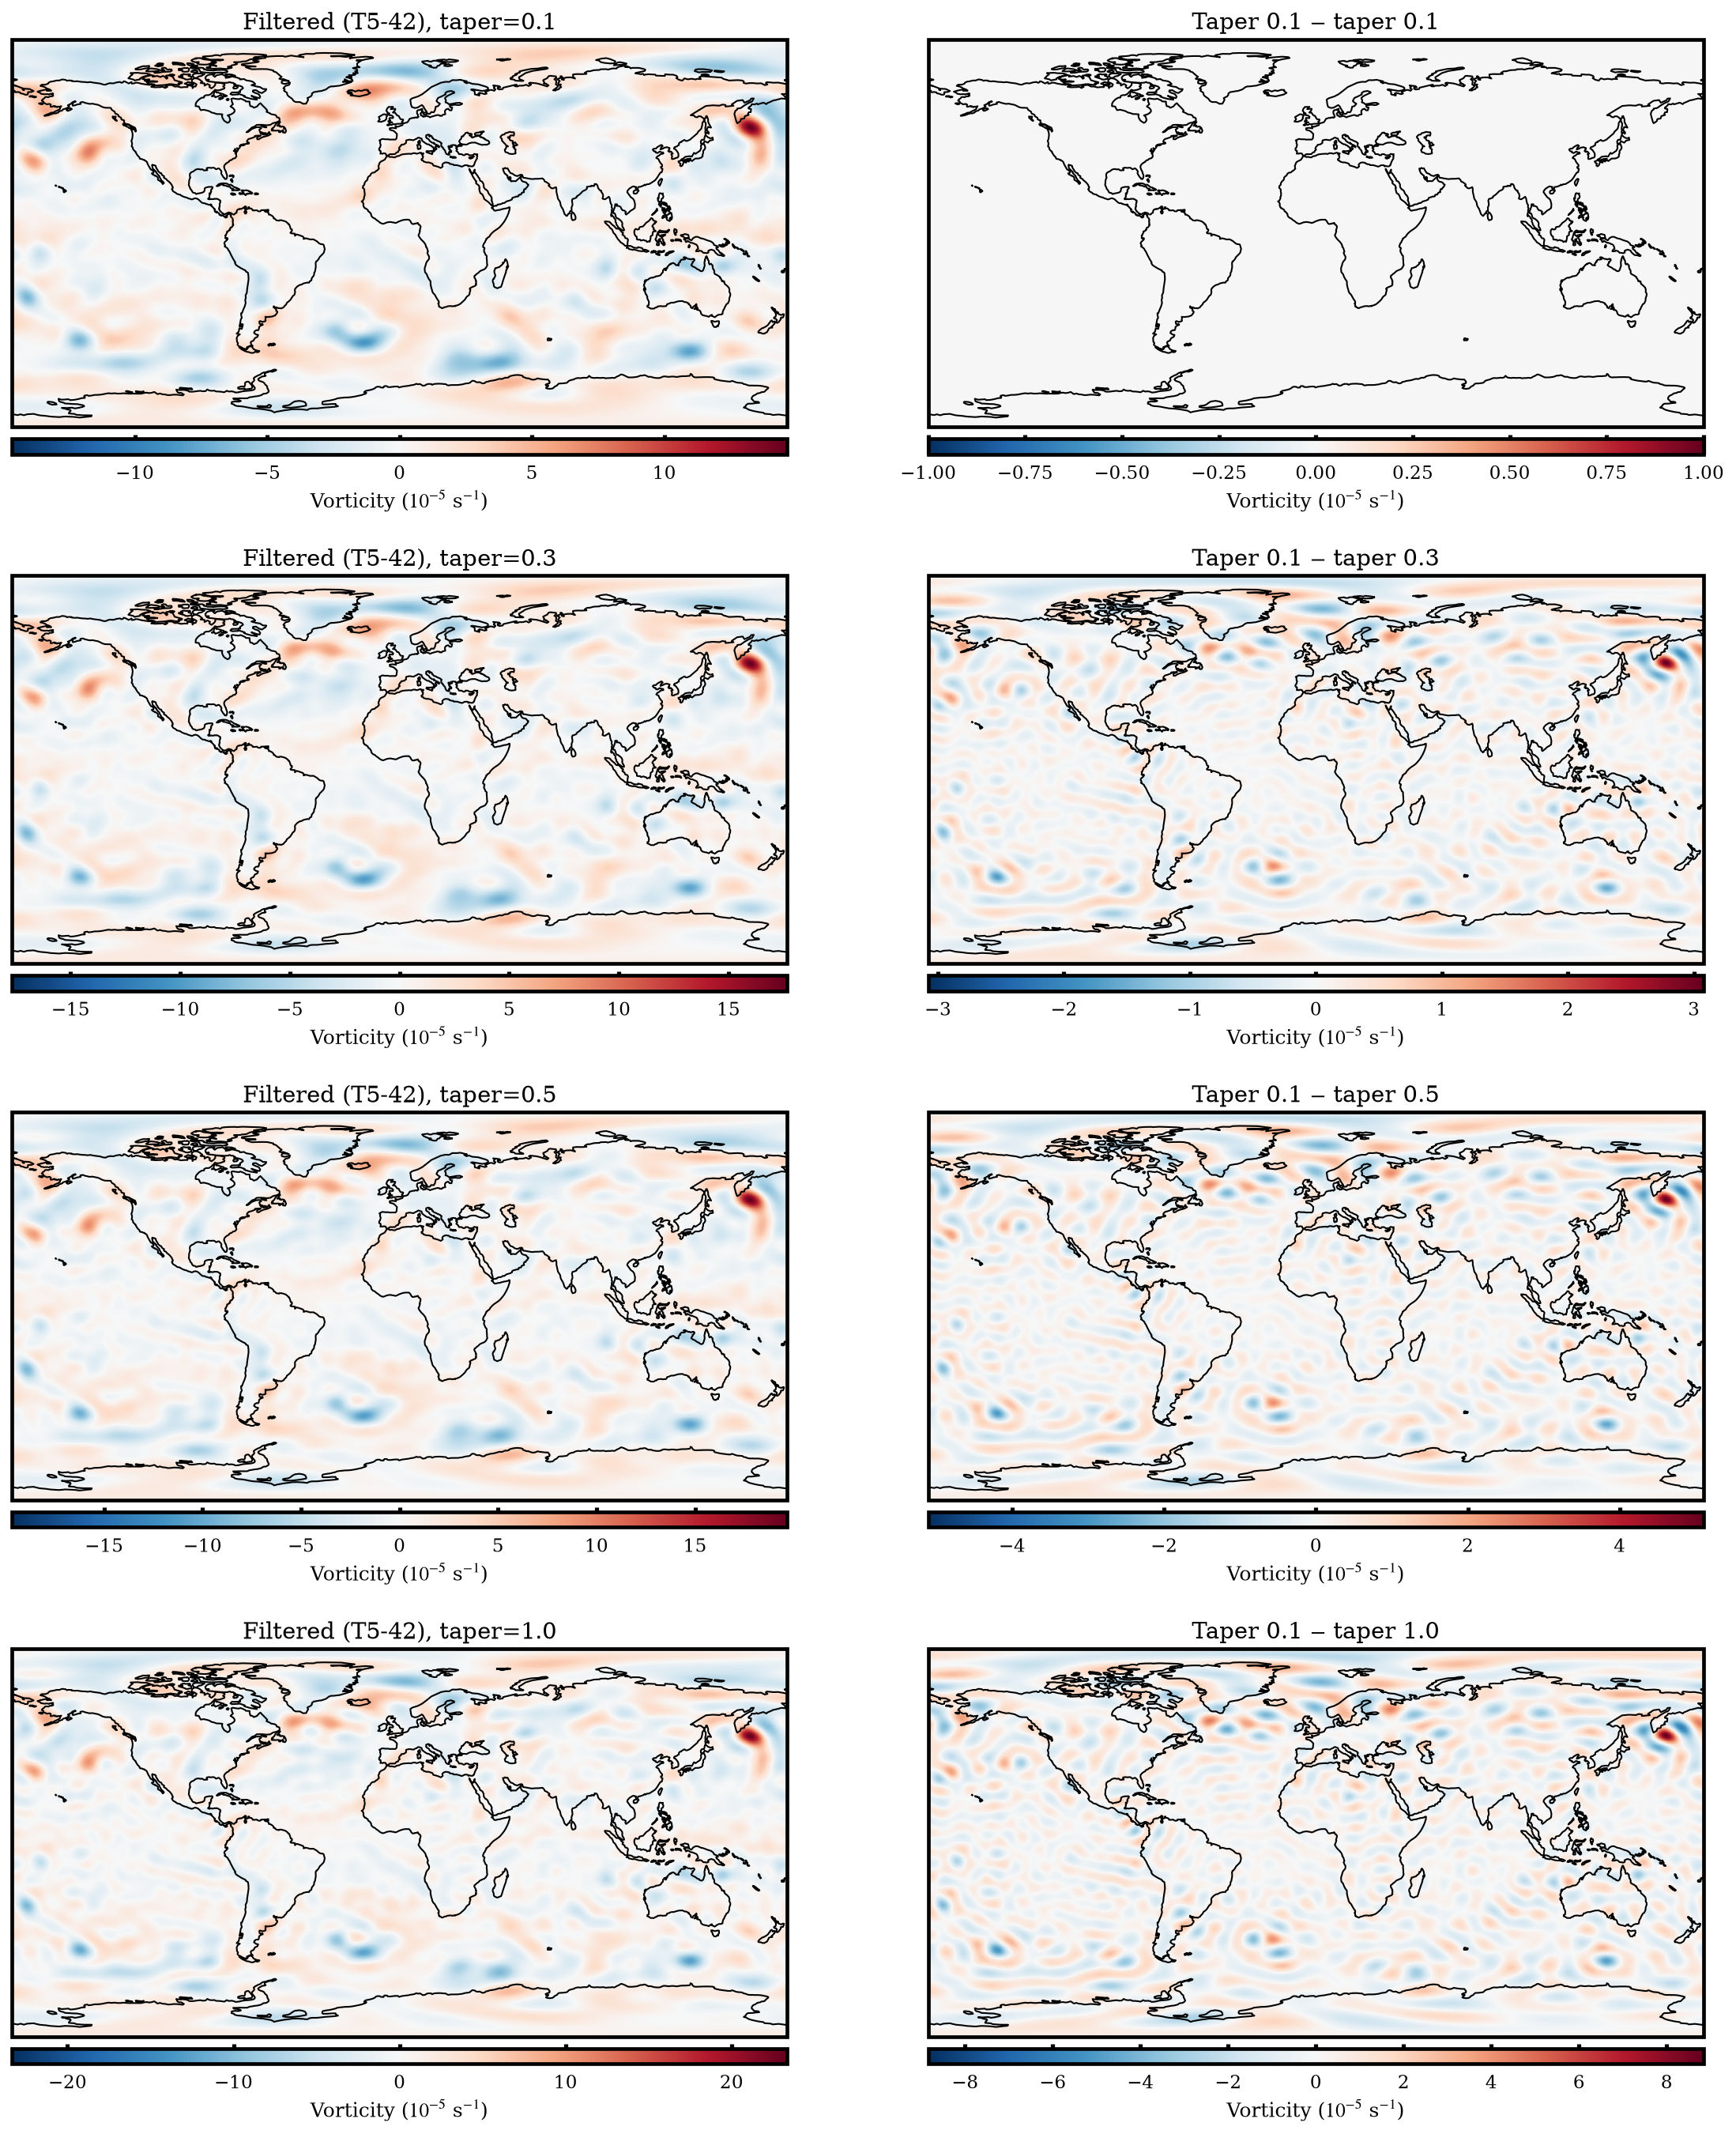

In [36]:
taper_vals = [0.1, 0.3, 0.5, 1.0]
label = r"Vorticity ($10^{-5}$ s$^{-1}$)"
pc = ccrs.PlateCarree()

reference = SHTFilter(lmin=6, lmax=42, taper_val=0.1).filter(vo)   # compute once

fig, ax = geo_map(projection=pc, nrows=len(taper_vals), ncols=2, width=16,
                  gridlines=False)   

for i, taper_val in enumerate(taper_vals):
    vo_filtered = SHTFilter(lmin=6, lmax=42, taper_val=taper_val).filter(vo)
    diff = vo_filtered - reference

    panels = [(vo_filtered, f"Filtered (T5-42), taper={taper_val}"),
              (diff,        f"Taper 0.1 $-$ taper {taper_val}")]

    for j, (da, title) in enumerate(panels):
        a = ax[i, j]
        vmax = float(abs(da).max()) or 1.0          # diff is all zeros for taper=0.1
        im = da.plot(ax=a, transform=pc, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                     add_colorbar=False)
        a.set_title(title, fontsize=14)
        add_colorbar(im, a, label=label, location="bottom", pad=0.1,
                     labelsize=12, ticksize=11)

plt.tight_layout()

plt.show()